# Naive Altitude and Vertical Velocity Estimation

We use a static recording (sensors sitting on a desk) to calculate the accelerometer and barometer's noise and drift. We then show how each sensor fails (when acting alone) during a stair-climbing demo. Press `shift + enter` to run each cell.

In [2]:
import numpy as np

import utils

## Settings

In [3]:
# Recordings (folders containing acc_baro.csv and meta.json)
STATIC_PATH = "recordings/static"
STAIRS_PATH = "recordings/stairs_up"

# Time to measure barometer and accelerometer reference points
REF_TIME_S = 2.0

## Analyze Static Recording

We load the static recording (sensors sitting on a desk), plot their measurements over time, and analyze the noise in each.

In [4]:
# Load the static recording
rec, rec_meta = utils.load_recording(STATIC_PATH)
t_acc = rec["t"]
az = rec["az"]

# Read barometer measurements (they are recorded at ~50Hz)
t_baro, baro = utils.baro_samples(rec)

# Print summary
print(f"Duration: {t_acc[-1]:.1f} s")
print(f"Accel samples: {len(t_acc)} ({(len(t_acc) - 1) / (t_acc[-1] - t_acc[0]):.1f} Hz)")
print(f"Baro samples: {len(t_baro)} ({(len(t_baro) - 1) / (t_baro[-1] - t_baro[0]):.1f} Hz)")

Duration: 300.0 s
Accel samples: 37371 (124.6 Hz)
Baro samples: 14986 (50.0 Hz)


Altitude reference: 1720.11 m
Gravity reference:  9.73 m/s²


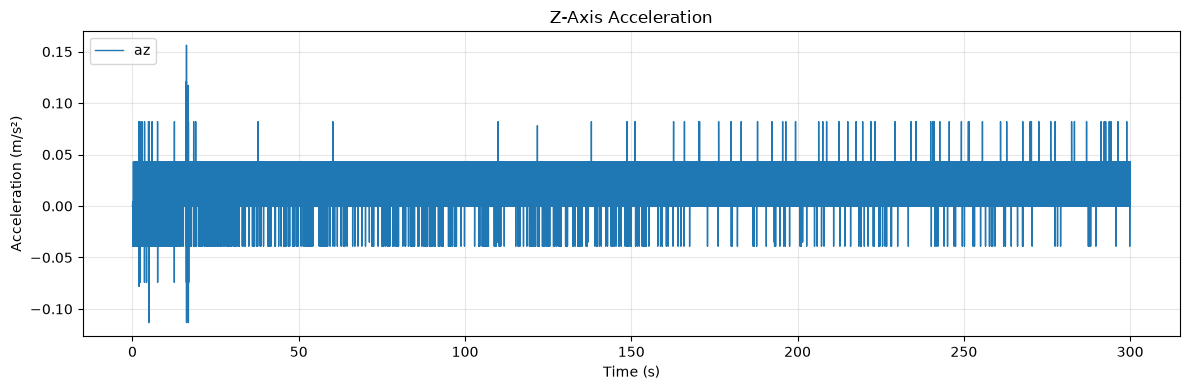

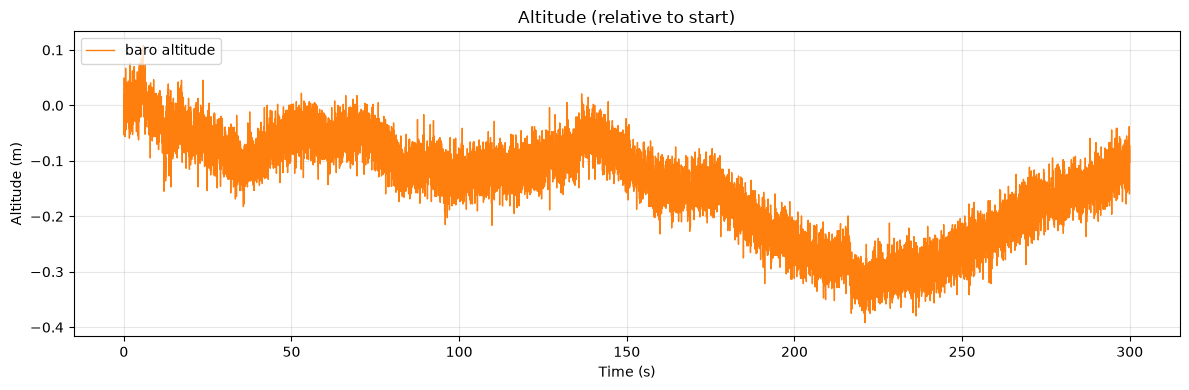

In [5]:
# Get altitude reference (zero point) by averaging readings in first few sec
baro_ref = np.mean(baro[t_baro < t_baro[0] + REF_TIME_S])
print(f"Altitude reference: {baro_ref:.2f} m")

# Subtract out reference to get the relative altitude
baro_rel = baro - baro_ref

# Get gravity acceleration reference by averaging readings in first few sec
g_ref = np.mean(az[t_acc < t_acc[0] + REF_TIME_S])
print(f"Gravity reference: {g_ref: .2f} m/s²")

# Subtract out gravity reference to get relative z-axis acceleration
az_rel = az - g_ref

# Plot raw acceleration and relative altitude
utils.plot_traces(
    [(t_acc, az_rel, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Z-Axis Acceleration",
)
utils.plot_traces(
    [(t_baro, baro_rel, "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Altitude (relative to start)",
)

In [7]:
# Compute the standard deviation (use sample-to-sample diff to negate drift)
sigma_a = np.std(np.diff(az_rel), ddof=1) / np.sqrt(2)
sigma_z = np.std(np.diff(baro_rel), ddof=1) / np.sqrt(2)
print(f"Accelerometer noise std dev (sigma_a): {sigma_a:.4f} m/s²")
print(f"Barometer noise std dev (sigma_z): {sigma_z:.4f} m")

Accelerometer noise std dev (sigma_a): 0.0212 m/s²
Barometer noise std dev (sigma_z): 0.0255 m


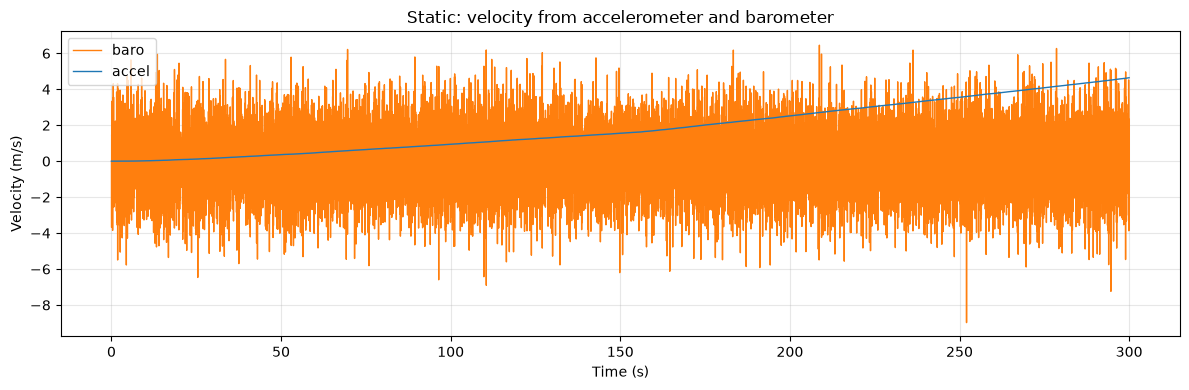

In [6]:
# Integrate relative acceleration to get vertical velocity (rectangle rule)
v_acc_rel = np.zeros(len(az_rel))
for k in range(1, len(az_rel)):
    dt = t_acc[k] - t_acc[k - 1]
    v_acc_rel[k] = v_acc_rel[k - 1] + az_rel[k - 1] * dt

# Differentiate barometer to get vertical velocity
v_baro_rel = np.zeros(len(baro_rel))
for k in range(1, len(baro_rel)):
    v_baro_rel[k] = (baro_rel[k] - baro_rel[k - 1]) / (t_baro[k] - t_baro[k - 1])

# Plot velocity computed from accelerometer and barometer
utils.plot_traces(
    [
        (t_baro, v_baro_rel, "baro", {"color": "tab:orange"}),
        (t_acc, v_acc_rel, "accel", {"color": "tab:blue"}),
    ],
    "Velocity (m/s)",
    title="Static: velocity from accelerometer and barometer",
)

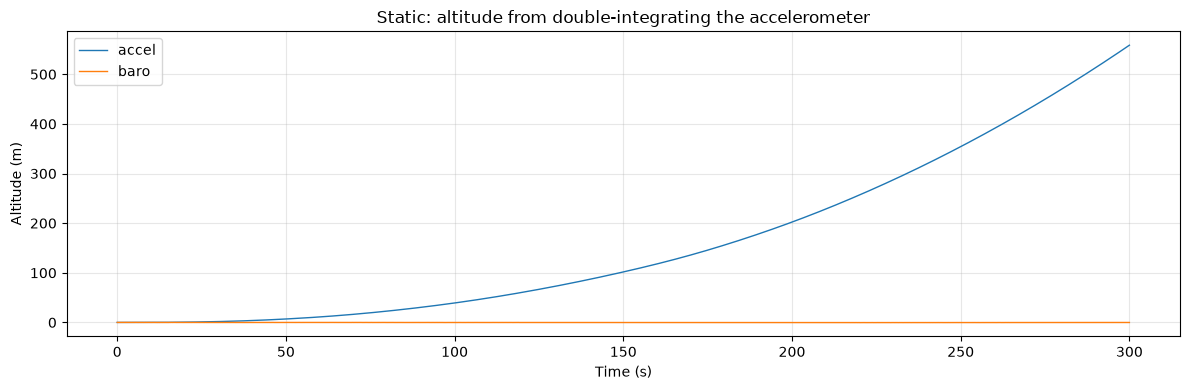

In [7]:
# Integrate velocity to get relative altitude (trapezoid rule)
h_acc_rel = np.zeros(len(v_acc_rel))
for k in range(1, len(v_acc_rel)):
    dt = t_acc[k] - t_acc[k - 1]
    h_acc_rel[k] = h_acc_rel[k - 1] + v_acc_rel[k - 1] * dt + \
        0.5 * az_rel[k - 1] * dt**2

# Plot altitude from the accelerometer vs. the barometer
utils.plot_traces(
    [
        (t_acc, h_acc_rel, "accel", {"color": "tab:blue"}),
        (t_baro, baro_rel, "baro", {"color": "tab:orange"}),
    ],
    "Altitude (m)",
    title="Static: altitude from double-integrating the accelerometer",
)

## Analyze Stair Climb Recording

Now, let's load the stair climb log and see how the accelerometer and barometer perform at estimating the height change and vertical velocity.

In [8]:
# Load the stair climb recording
rec, rec_meta = utils.load_recording(STAIRS_PATH)
t_acc = rec["t"]
az = rec["az"]

# Read barometer measurements (they are recorded at ~50Hz)
t_baro, baro = utils.baro_samples(rec)

# Print summary
print(f"Duration: {t_acc[-1]:.1f} s")
print(f"Accel samples: {len(t_acc)} ({(len(t_acc) - 1) / (t_acc[-1] - t_acc[0]):.1f} Hz)")
print(f"Baro samples: {len(t_baro)} ({(len(t_baro) - 1) / (t_baro[-1] - t_baro[0]):.1f} Hz)")

Duration: 20.0 s
Accel samples: 2491 (124.5 Hz)
Baro samples: 998 (49.9 Hz)


Altitude reference: 1718.34 m
Gravity reference:  9.76 m/s²


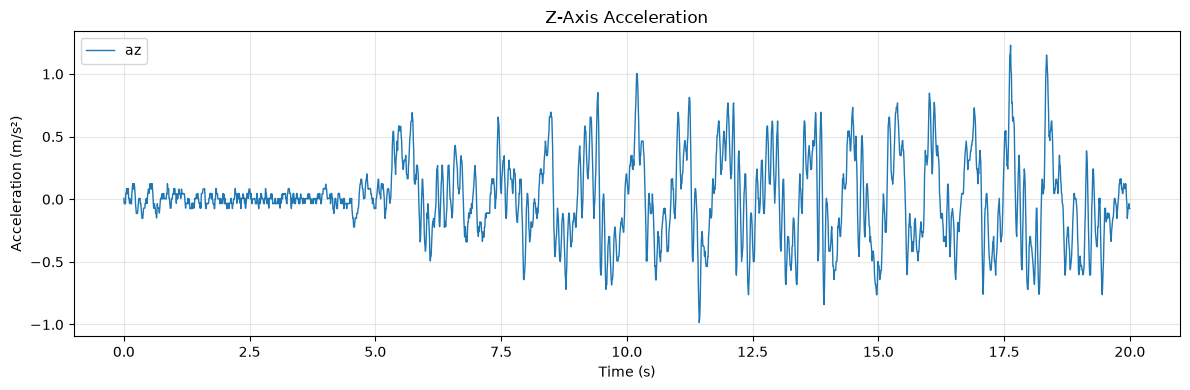

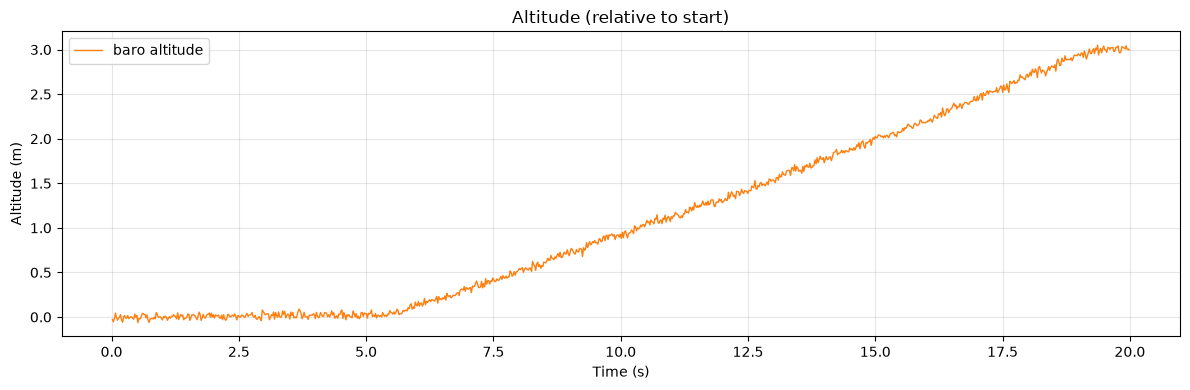

In [9]:
# Get altitude reference (zero point) by averaging readings in first few sec
baro_ref = np.mean(baro[t_baro < t_baro[0] + REF_TIME_S])
print(f"Altitude reference: {baro_ref:.2f} m")

# Subtract out reference to get the relative altitude
baro_rel = baro - baro_ref

# Get gravity acceleration reference by averaging readings in first few sec
g_ref = np.mean(az[t_acc < t_acc[0] + REF_TIME_S])
print(f"Gravity reference: {g_ref: .2f} m/s²")

# Subtract out gravity reference to get relative z-axis acceleration
az_rel = az - g_ref

# Plot raw acceleration and relative altitude
utils.plot_traces(
    [(t_acc, az_rel, "az", {"color": "tab:blue"})],
    "Acceleration (m/s²)",
    title="Z-Axis Acceleration",
)
utils.plot_traces(
    [(t_baro, baro_rel, "baro altitude", {"color": "tab:orange"})],
    "Altitude (m)",
    title="Altitude (relative to start)",
)

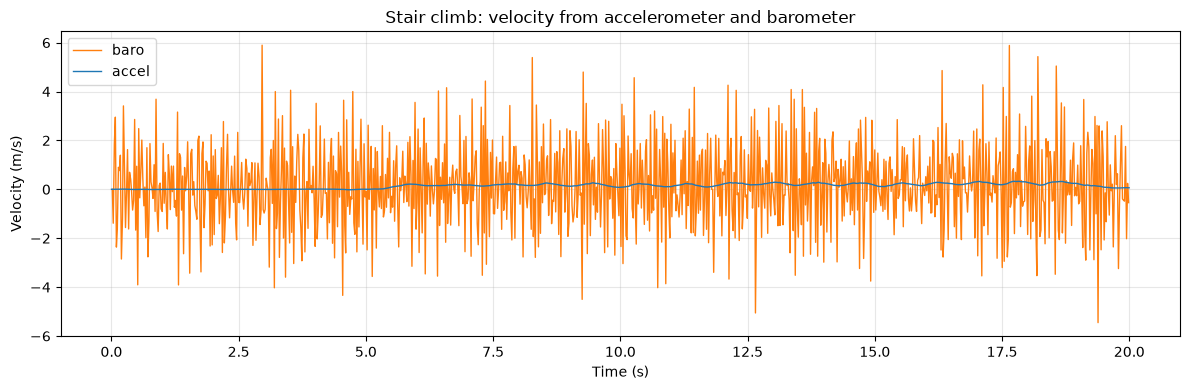

In [10]:
# Integrate relative acceleration to get vertical velocity (rectangle rule)
v_acc_rel = np.zeros(len(az_rel))
for k in range(1, len(az_rel)):
    dt = t_acc[k] - t_acc[k - 1]
    v_acc_rel[k] = v_acc_rel[k - 1] + az_rel[k - 1] * dt

# Differentiate barometer to get vertical velocity
v_baro_rel = np.zeros(len(baro_rel))
for k in range(1, len(baro_rel)):
    v_baro_rel[k] = (baro_rel[k] - baro_rel[k - 1]) / (t_baro[k] - t_baro[k - 1])

# Plot velocity computed from accelerometer and barometer
utils.plot_traces(
    [
        (t_baro, v_baro_rel, "baro", {"color": "tab:orange"}),
        (t_acc, v_acc_rel, "accel", {"color": "tab:blue"}),
    ],
    "Velocity (m/s)",
    title="Stair climb: velocity from accelerometer and barometer",
)

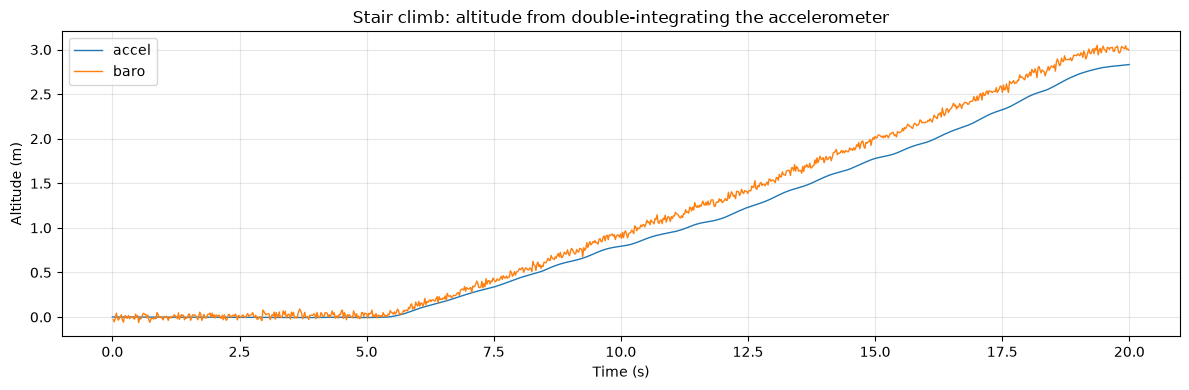

In [11]:
# Integrate velocity to get relative altitude (trapezoid rule)
h_acc_rel = np.zeros(len(v_acc_rel))
for k in range(1, len(v_acc_rel)):
    dt = t_acc[k] - t_acc[k - 1]
    h_acc_rel[k] = h_acc_rel[k - 1] + v_acc_rel[k - 1] * dt + \
        0.5 * az_rel[k - 1] * dt**2

# Plot altitude from the accelerometer vs. the barometer
utils.plot_traces(
    [
        (t_acc, h_acc_rel, "accel", {"color": "tab:blue"}),
        (t_baro, baro_rel, "baro", {"color": "tab:orange"}),
    ],
    "Altitude (m)",
    title="Stair climb: altitude from double-integrating the accelerometer",
)

## Takeaways

The accelerometer is good for measuring movement in the short term but drifts in the long term. The barometer is noisy in the short term, but it stays bounded in the long term (it wanders with the air pressure within limits). We could smooth it with a moving average filter (MAF), but that adds lag to the estimates.

| | Accelerometer | Barometer |
|---|---|---|
| Short term | Responsive | Noisy |
| Long term | Drifts | Wanders (stays bounded) |
| Altitude | Only for a few seconds | Good (if averaged) |
| Velocity | Good for a few seconds, then drifts | Very noisy (laggy if averaged) |